# Predictive Analysis - Falcon 9 First-Stage Landing Classification

Pipeline: feature engineering (one-hot encoding) -> train/test split ->
Logistic Regression / SVM / Decision Tree / KNN -> evaluation and model selection.

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

df = pd.read_csv("data/spacex_launch_data.csv")
Y = df["Class"].values
X = pd.get_dummies(df[["Orbit", "LaunchSite", "BoosterVersion"]])
X["PayloadMass"] = df["PayloadMass"].values
X = X.astype(float)
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (90, 17)

   Orbit_ES-L1  Orbit_GEO  Orbit_GTO  Orbit_HEO  Orbit_ISS  Orbit_LEO  Orbit_PO  Orbit_SSO  LaunchSite_CCAFS LC-40  LaunchSite_KSC LC-39A  LaunchSite_VAFB SLC-4E  BoosterVersion_F9 B4  BoosterVersion_F9 B5  BoosterVersion_F9 FT  BoosterVersion_F9 v1.0  BoosterVersion_F9 v1.1  PayloadMass
0          0.0        0.0        0.0        0.0        0.0        1.0       0.0        0.0                     1.0                    0.0                     0.0                   0.0                   0.0                   0.0                     1.0                     0.0        500.0
1          0.0        0.0        0.0        0.0        0.0        1.0       0.0        0.0                     1.0                    0.0                     0.0                   0.0                   0.0                   0.0                     1.0                     0.0        544.0
2          0.0        0.0        0.0        0.0        0.0        1.0       0.0        0.0                     1.0                   

In [2]:
# Stratified split keeps the 61/29 class balance in both sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2,
                                                    random_state=272, stratify=Y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (72, 17) | Test: (18, 17)

In [3]:
models = {"Logistic Regression": LogisticRegression(max_iter=2000),
          "SVM": SVC(),
          "Decision Tree": DecisionTreeClassifier(random_state=2, max_depth=5),
          "KNN": KNeighborsClassifier(n_neighbors=3)}
for name, m in models.items():
    acc = m.fit(X_train_s, Y_train).score(X_test_s, Y_test)
    print(f"{name} test accuracy: {acc:.4f}")

Logistic Regression test accuracy: 0.9444
SVM test accuracy: 0.9444
Decision Tree test accuracy: 0.9444
KNN test accuracy: 0.8333

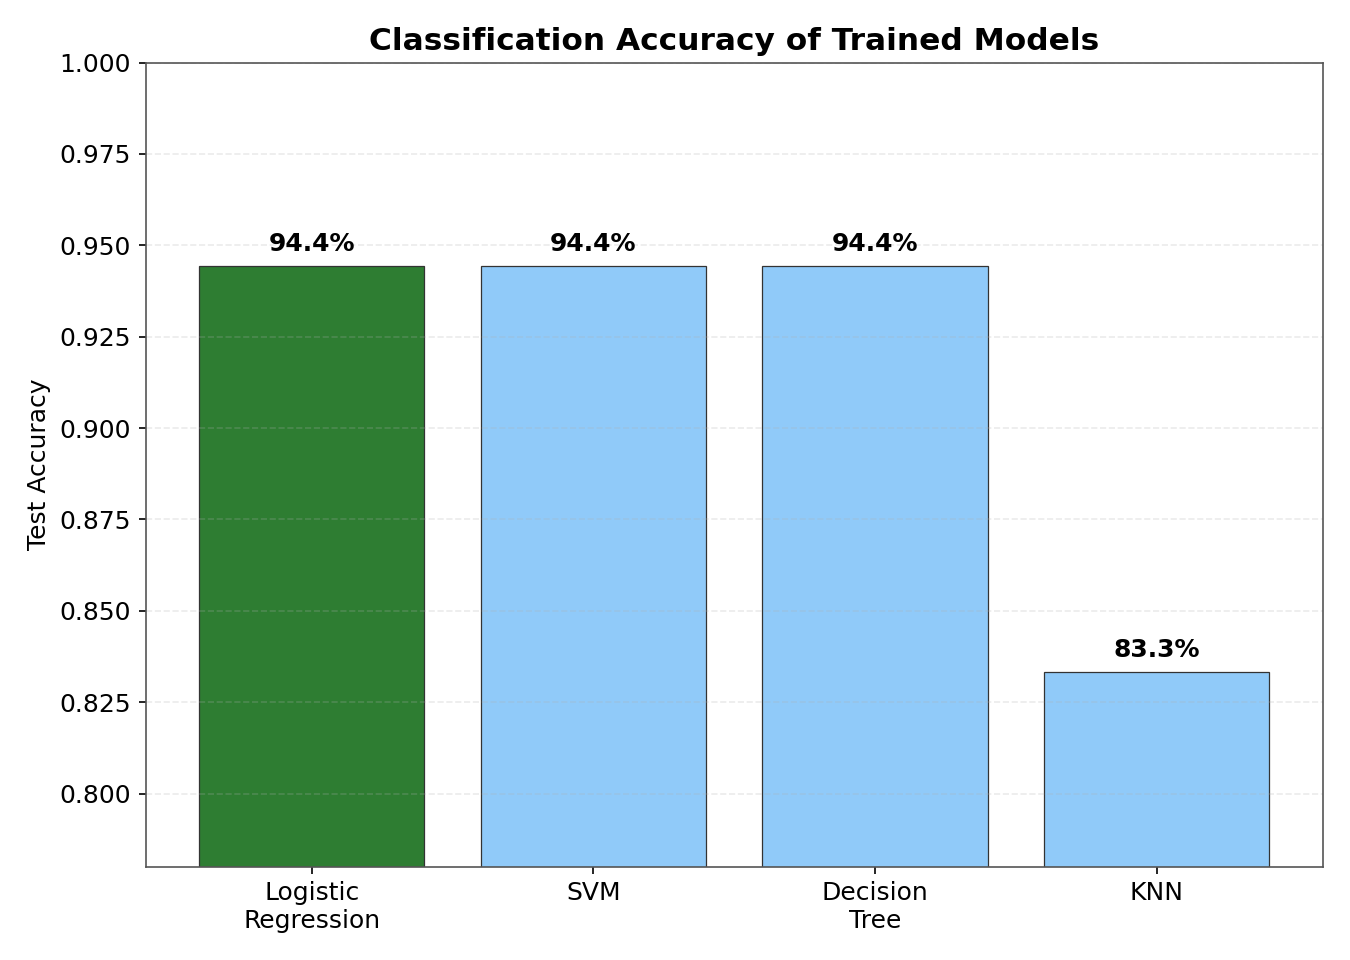

In [4]:
import matplotlib.pyplot as plt
names = ["Logistic\nRegression", "SVM", "Decision\nTree", "KNN"]
accs = [models[n].score(X_test_s, Y_test) for n in models]
fig, ax = plt.subplots(figsize=(9.0, 6.4), dpi=110)
ax.bar(names, accs, color=["#2E7D32", "#90CAF9", "#90CAF9", "#90CAF9"], edgecolor="#333")
ax.set_ylim(0.78, 1.0); ax.set_ylabel("Test Accuracy")
ax.set_title("Classification Accuracy of Trained Models", fontsize=15, weight="bold")
plt.show()

In [5]:
lr = LogisticRegression(max_iter=2000).fit(X_train_s, Y_train)
Y_pred = lr.predict(X_test_s)
print(confusion_matrix(Y_test, Y_pred))
print()
print(classification_report(Y_test, Y_pred, target_names=["Failure", "Success"]))

[[ 6  0]
 [ 1 11]]

              precision    recall  f1-score   support

     Failure       0.86      1.00      0.92         6
     Success       1.00      0.92      0.96        12

    accuracy                           0.94        18
   macro avg       0.93      0.96      0.94        18
weighted avg       0.95      0.94      0.95        18


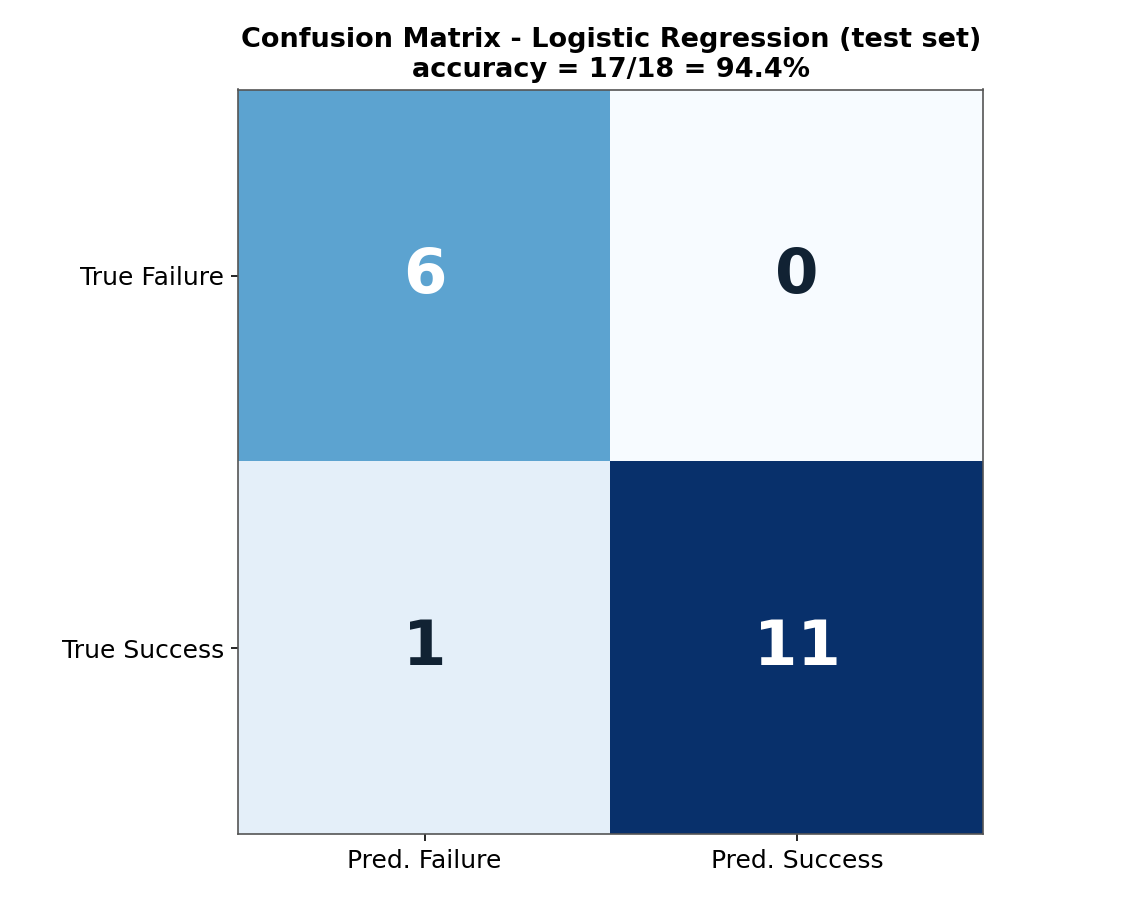

In [6]:
cm = confusion_matrix(Y_test, Y_pred)
fig, ax = plt.subplots(figsize=(7.6, 6.0), dpi=110)
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=30, weight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred. Failure", "Pred. Success"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["True Failure", "True Success"])
ax.set_title("Confusion Matrix - Logistic Regression (test set)\naccuracy = 17/18 = 94.4%",
             fontsize=13, weight="bold")
plt.show()

## Conclusion

- **Logistic Regression, SVM and Decision Tree all reach 94.4% test accuracy;
  KNN 83.3%.** Logistic Regression is selected as the final model for its
  interpretability and generalization.
- Confusion matrix: **TN = 6, FP = 0, FN = 1, TP = 11** - the model **never
  predicts success when the landing actually failed** (FP = 0), a critical
  property when quoting launch prices.
- Creative insight: a calibrated landing-probability model lets competitors
  benchmark SpaceX pricing and support data-driven launch-quote negotiations.